# 05. 3주차 보충 실험: 단순해진 모델 위에서 A~D 다시 시험

### 왜 다시 하나요?
3주차에는 새 피처 A~D를 **복잡한 설정(과적합되기 쉬운 상태)** 에서 먼저 시험하고, 과적합 방지 설정(E)은 마지막에 넣었어요.
피처를 늘리면 **외울 거리도 늘어나서**, 복잡한 모델에서는 새 피처가 "외우기"에 쓰였을 수 있어요.
그래서 이번에는 **E(과적합 방지 설정)를 먼저 적용한 모델**을 출발점으로 A~D를 다시 시험합니다.

### 출발점
- 3주차 최종 모델: 1주차 − dayofyear + **과적합 방지 설정** (평균 SMAPE 약 0.534)
- 판정 규칙은 그대로 (시드 3개, 흔들림의 2배 이상 좋아져야 ✅)

### 순서 (3주차와 동일하게 하나씩 쌓기)
```
기준(E 적용) → + A 추세 → + B 영업장 흐름 → + C 영업장 상태 → + D 단체 메뉴
```

### 결과 읽는 법
- **이번엔 ✅가 나온다** → 3주차에 효과가 없던 건 피처가 나빠서가 아니라 **모델이 외우기 쉬운 상태였기 때문**
- **이번에도 ➖ / ❌** → 피처에 담긴 정보가 이미 기존 피처에 있거나, 배울 예시가 부족한 것 (3주차 해석이 맞았음)

어느 쪽이 나와도 의미 있는 결과예요.

> ⏱️ 모델을 약 45번 학습해서 **30~45분** 걸려요.

## 0. 환경 설정

In [1]:
# ▶ Google Colab에서만 실행되는 셀입니다 (내 컴퓨터에서는 아무 일도 안 함).
#   구글 드라이브 연결 팝업이 뜨면 '허용'을 눌러주세요.
import sys
if 'google.colab' in sys.modules:
    !pip install -q koreanize-matplotlib
    from google.colab import drive
    drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 53.7 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
import os, sys, time, warnings
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
try:
    import koreanize_matplotlib
except ImportError:
    if platform.system() == 'Windows': plt.rc('font', family='Malgun Gothic')
    elif platform.system() == 'Darwin': plt.rc('font', family='AppleGothic')
plt.rc('axes', unicode_minus=False)

IN_COLAB = 'google.colab' in sys.modules
BASE_DIR = Path('/content/drive/MyDrive/capstone') if IN_COLAB else Path('..')
DATA_DIR = Path(os.environ.get('DATA_DIR', BASE_DIR / 'data'))
FIG_DIR = Path(os.environ.get('FIG_DIR', BASE_DIR / 'figures'))
RESULT_DIR = Path(os.environ.get('RESULT_DIR', BASE_DIR / 'results'))
for d in [FIG_DIR, RESULT_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print('LightGBM', lgb.__version__, '| train.csv 존재 여부:', (DATA_DIR / 'train' / 'train.csv').exists())

import re
SUB_DIR = Path(os.environ.get('SUB_DIR', BASE_DIR / 'submissions')); SUB_DIR.mkdir(parents=True, exist_ok=True)

LightGBM 4.6.0 | train.csv 존재 여부: True


## 1. 데이터 · 평가지표 · fold 준비 (3주차와 동일)

In [3]:
KR_HOLIDAYS = pd.to_datetime([
    '2023-01-01','2023-01-21','2023-01-22','2023-01-23','2023-01-24','2023-03-01','2023-05-05','2023-05-27',
    '2023-05-29','2023-06-06','2023-08-15','2023-09-28','2023-09-29','2023-09-30','2023-10-02','2023-10-03',
    '2023-10-09','2023-12-25','2024-01-01','2024-02-09','2024-02-10','2024-02-11','2024-02-12','2024-03-01',
    '2024-04-10','2024-05-05','2024-05-06','2024-05-15','2024-06-06',
    # TEST 기간(2024-06 ~ 2025-06) 공휴일
    '2024-08-15','2024-09-16','2024-09-17','2024-09-18','2024-10-01','2024-10-03','2024-10-09','2024-12-25',
    '2025-01-01','2025-01-27','2025-01-28','2025-01-29','2025-01-30','2025-03-01','2025-03-03','2025-05-05',
    '2025-05-06','2025-06-03','2025-06-06'])
HOLIDAY_SET = set(KR_HOLIDAYS)

train = pd.read_csv(DATA_DIR / 'train' / 'train.csv')
train['영업일자'] = pd.to_datetime(train['영업일자'])
train['매출수량'] = train['매출수량'].clip(lower=0)
wide = (train.pivot_table(index='영업일자', columns='영업장명_메뉴명', values='매출수량', aggfunc='sum')
             .sort_index().asfreq('D').fillna(0))
MENUS = wide.columns.tolist()
VENUE_OF = {m: m.split('_', 1)[0] for m in MENUS}
VENUES = sorted(set(VENUE_OF.values()))
MENU_VENUE = np.array([VENUE_OF[m] for m in MENUS])
VENUE_IDX = np.array([VENUES.index(v) for v in MENU_VENUE])      # 메뉴 → 영업장 번호
IS_GROUP = np.array(['단체' in m for m in MENUS]).astype(int)       # 단체 메뉴 표시
W = wide.values.astype(np.float32)
DATES = wide.index
M, V = len(MENUS), len(VENUES)
INPUT_LEN, HORIZON = 28, 7
FOLDS = [('2023-10-01', '2023-12-31'), ('2024-01-01', '2024-03-31'), ('2024-04-01', '2024-06-09')]
print('메뉴', M, '| 영업장', V, '| 단체 메뉴 수', IS_GROUP.sum())

def smape_1d(y_true, y_pred):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    yt, yp = y_true[mask], y_pred[mask]
    return np.mean(2 * np.abs(yt - yp) / (np.abs(yt) + np.abs(yp)))

def venue_smape(T, P):
    scores = {}
    for v in VENUES:
        idx = np.where(MENU_VENUE == v)[0]
        s = [smape_1d(T[:, i], P[:, i]) for i in idx]
        s = [x for x in s if not np.isnan(x)]
        if s:
            scores[v] = float(np.mean(s))
    return float(np.mean(list(scores.values()))), scores

def fold_origins(val_start, val_end):
    vs, ve = DATES.get_loc(pd.Timestamp(val_start)), DATES.get_loc(pd.Timestamp(val_end))
    return list(range(INPUT_LEN, vs - HORIZON + 1)), list(range(vs, ve - HORIZON + 2, 7))

메뉴 193 | 영업장 9 | 단체 메뉴 수 13


## 2. 피처 만들기 (3주차와 동일)

In [4]:
MENU_CAT = pd.CategoricalDtype(MENUS); VENUE_CAT = pd.CategoricalDtype(VENUES)
GROUPS = {
    'A_추세': ['trend_7_28', 'trend_7_prev7', 'trend_sold_7_28'],
    'B_영업장흐름': ['venue_mean_7', 'venue_mean_28', 'venue_trend_7_28', 'venue_active_ratio_7', 'menu_share_28'],
    'C_영업장상태': ['venue_closed_7', 'venue_zero_days_28', 'venue_days_since_reopen'],
    'D_단체메뉴': ['is_group'],
}
ALL_NEW = sum(GROUPS.values(), [])

def venue_status(vx):
    """vx: (28, 영업장 수) 영업장별 하루 총판매 → 영업장별 상태 피처 3개"""
    closed7 = (vx[-7:].sum(0) == 0).astype(int)
    zero_days = (vx == 0).sum(0)
    since = np.full(vx.shape[1], INPUT_LEN + 1)
    for j in range(vx.shape[1]):
        z = vx[:, j] == 0
        run, end_of_long = 0, None                    # 7일 이상 연속 0이 끝난 위치 찾기
        for t in range(INPUT_LEN):
            run = run + 1 if z[t] else 0
            if run >= 7 and (t == INPUT_LEN - 1 or not z[t + 1]):
                end_of_long = t
        if end_of_long is not None:
            since[j] = 0 if end_of_long == INPUT_LEN - 1 else INPUT_LEN - 1 - end_of_long
    return closed7, zero_days, since

def make_features(inp, start_date):
    """inp: (28, 메뉴 수). 반환: 7 × 메뉴 수 행"""
    x = np.asarray(inp, dtype=np.float32).T                      # (메뉴, 28)
    vx = np.stack([x[VENUE_IDX == j].sum(0) for j in range(V)], 1)  # (28, 영업장)
    F = {f'lag_{k}': x[:, INPUT_LEN - k] for k in range(1, INPUT_LEN + 1)}
    for w in (7, 14, 28):
        y = x[:, -w:]; cnt = (y > 0).sum(1)
        F[f'mean_{w}'] = y.mean(1)
        F[f'sold_mean_{w}'] = np.where(cnt > 0, y.sum(1) / np.maximum(cnt, 1), 0)
        F[f'sold_ratio_{w}'] = cnt / w
    with np.errstate(all='ignore'):
        F['sold_median_28'] = np.nan_to_num(np.nanmedian(np.where(x > 0, x, np.nan), axis=1))
    F['std_28'] = x.std(1); F['max_28'] = x.max(1)
    F['days_since_sale'] = np.array([INPUT_LEN - np.nonzero(r)[0][-1] if r.any() else INPUT_LEN + 1 for r in x])
    # A. 추세
    F['trend_7_28'] = (F['mean_7'] + 1) / (F['mean_28'] + 1)
    F['trend_7_prev7'] = (x[:, -7:].sum(1) + 1) / (x[:, -14:-7].sum(1) + 1)
    F['trend_sold_7_28'] = (F['sold_mean_7'] + 1) / (F['sold_mean_28'] + 1)
    # B. 영업장 흐름
    v7, v28 = vx[-7:].mean(0), vx.mean(0)
    n_menu_v = np.bincount(VENUE_IDX, minlength=V)
    active7 = np.bincount(VENUE_IDX, weights=(x[:, -7:].sum(1) > 0), minlength=V) / n_menu_v
    F['venue_mean_7'] = v7[VENUE_IDX]; F['venue_mean_28'] = v28[VENUE_IDX]
    F['venue_trend_7_28'] = ((v7 + 1) / (v28 + 1))[VENUE_IDX]
    F['venue_active_ratio_7'] = active7[VENUE_IDX]
    F['menu_share_28'] = x.sum(1) / np.maximum(vx.sum(0)[VENUE_IDX], 1)
    # C. 영업장 상태
    closed7, zero_days, since = venue_status(vx)
    F['venue_closed_7'] = closed7[VENUE_IDX]; F['venue_zero_days_28'] = zero_days[VENUE_IDX]
    F['venue_days_since_reopen'] = since[VENUE_IDX]
    # D. 단체 메뉴
    F['is_group'] = IS_GROUP
    base = pd.DataFrame(F)
    base['menu'] = pd.Categorical(MENUS, dtype=MENU_CAT)
    base['venue'] = pd.Categorical(list(MENU_VENUE), dtype=VENUE_CAT)
    frames = []
    for h in range(1, HORIZON + 1):
        d = start_date + pd.Timedelta(days=h - 1); f = base.copy()
        f['h'] = h; f['dow'] = d.dayofweek; f['month'] = d.month       # dayofyear는 2주차 결과에 따라 제외
        f['is_weekend'] = int(d.dayofweek >= 5); f['is_holiday'] = int(d in HOLIDAY_SET)
        idx = [h - 1, h + 6, h + 13, h + 20]
        f['same_dow_last'] = x[:, h + 20]; f['same_dow_mean4'] = x[:, idx].mean(1)
        f['same_dow_sold_ratio'] = (x[:, idx] > 0).mean(1)
        frames.append(f)
    return pd.concat(frames, ignore_index=True)

def build_dataset(origins):
    X = pd.concat([make_features(W[o - INPUT_LEN:o], DATES[o]) for o in origins], ignore_index=True)
    y = np.concatenate([W[o:o + HORIZON].reshape(-1) for o in origins])
    return X, y

BASE_COLS = [c for c in make_features(W[:INPUT_LEN], DATES[INPUT_LEN]).columns if c not in ALL_NEW]
print('기존 피처 수:', len(BASE_COLS), '| 새 피처 수:', len(ALL_NEW))

기존 피처 수: 51 | 새 피처 수: 12


In [5]:
t0 = time.time()
FOLD_DATA = []
for a, b in FOLDS:
    tr_o, va_o = fold_origins(a, b)
    X_tr, y_tr = build_dataset(tr_o)
    X_va, y_va = build_dataset(va_o)
    FOLD_DATA.append(dict(val_o=va_o, X_tr=X_tr, y_tr=y_tr, X_va=X_va, y_va=y_va))
print(f'학습 데이터 준비 완료 ({time.time() - t0:.0f}초)')

학습 데이터 준비 완료 (37초)


## 3. 실험 도구 (3주차와 동일)

In [6]:
PARAMS = dict(objective='regression', learning_rate=0.05, n_estimators=600,
              num_leaves=63, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              importance_type='gain', verbose=-1)
SEEDS = [42, 2024, 7]

def run_cv(cols, params=PARAMS, floor=False, seeds=SEEDS, preds_in=None):
    """preds_in이 주어지면 다시 학습하지 않고 그 예측값에 보정만 적용"""
    scores, preds = {}, {}
    for seed in seeds:
        row = {}
        for fi, d in enumerate(FOLD_DATA):
            if preds_in is None:
                mask = d['y_tr'] > 0
                model = lgb.LGBMRegressor(**params, random_state=seed)
                model.fit(d['X_tr'].loc[mask, cols], np.log1p(d['y_tr'][mask]))
                P = np.clip(np.expm1(model.predict(d['X_va'][cols])), 0, None).reshape(-1, M)
            else:
                P = preds_in[(seed, fi)]
            preds[(seed, fi)] = P
            P_eval = np.maximum(P, 1) if floor else P
            row[f'fold{fi + 1}'] = venue_smape(d['y_va'].reshape(-1, M), P_eval)[0]
        scores[f'seed{seed}'] = row
        print(f'  seed {seed}: ' + ', '.join(f'{k}={v:.4f}' for k, v in row.items()))
    return pd.DataFrame(scores).T, preds

def judge(name, new, base, noise):
    nm, bm = new.mean(), base.mean()
    delta = nm - bm
    th = 2 * noise[delta.index]
    worse = (delta > th).sum()
    avg_delta, avg_th = delta.mean(), 2 * noise.mean()
    if avg_delta < -avg_th and worse == 0:
        verdict = '✅ 개선'
    elif avg_delta < -avg_th and worse > 0:
        verdict = '⚠️ 평균은 좋아졌지만 나빠진 fold 있음'
    elif avg_delta > avg_th:
        verdict = '❌ 악화'
    else:
        verdict = '➖ 차이 없음 (노이즈 범위)'
    print(f'[{name}] 평균 차이 {avg_delta:+.4f} (기준 ±{avg_th:.4f}) → {verdict}')
    if delta['fold3'] > th['fold3']:
        print('   ⚠️ fold3(봄) 점수가 나빠졌어요 → TEST_08·09(봄) 예측에 불리할 수 있음')
    display(pd.DataFrame({'기존': bm, '새 실험': nm, '차이': delta, '확실한 변화 기준(±)': th}).round(4))
    return verdict

## 4. 기준점 측정: 과적합 방지 설정을 먼저 적용

In [7]:
REG_PARAMS = {**PARAMS, 'num_leaves': 31, 'min_child_samples': 100, 'reg_lambda': 1.0, 'colsample_bytree': 0.7}
print('기준 모델 (1주차 − dayofyear + 과적합 방지 설정) × 시드 3개')
best_cols, best_params, best_floor = BASE_COLS.copy(), REG_PARAMS, False
best_scores, best_preds = run_cv(best_cols, best_params)
NOISE = best_scores.std()
print(f'평균 SMAPE {best_scores.mean().mean():.4f} | 흔들림 평균 {NOISE.mean():.4f} → 기준 ±{2 * NOISE.mean():.4f}')
print('→ 3주차의 "E_과적합방지설정" 결과(평균 약 0.534)와 거의 같아야 정상')
BASE_SCORES, BASE_PREDS = best_scores.copy(), best_preds
LOG = [dict(단계='기준 (E 적용)', **best_scores.mean().round(4).to_dict(),
            평균=round(best_scores.mean().mean(), 4), 판정='기준', 채택='-')]

기준 모델 (1주차 − dayofyear + 과적합 방지 설정) × 시드 3개
  seed 42: fold1=0.5874, fold2=0.5018, fold3=0.5196
  seed 2024: fold1=0.5842, fold2=0.4960, fold3=0.5186
  seed 7: fold1=0.5802, fold2=0.4980, fold3=0.5190
평균 SMAPE 0.5339 | 흔들림 평균 0.0023 → 기준 ±0.0047
→ 3주차의 "E_과적합방지설정" 결과(평균 약 0.534)와 거의 같아야 정상


## 5. A → B → C → D 다시 시험 (하나씩 쌓기)

In [8]:
def try_step(name, cols=None, params=None, floor=None, reuse_preds=False):
    global best_cols, best_params, best_floor, best_scores, best_preds
    cols = best_cols if cols is None else cols
    params = best_params if params is None else params
    floor = best_floor if floor is None else floor
    print(f'\n===== {name} =====')
    new_scores, new_preds = run_cv(cols, params, floor, preds_in=best_preds if reuse_preds else None)
    verdict = judge(name, new_scores, best_scores, NOISE)
    adopted = verdict.startswith('✅')
    LOG.append(dict(단계=name, **new_scores.mean().round(4).to_dict(), 평균=round(new_scores.mean().mean(), 4),
                    판정=verdict, 채택='O' if adopted else 'X'))
    if adopted:
        best_cols, best_params, best_floor = cols, params, floor
        best_scores, best_preds = new_scores, new_preds
        print('   → 채택! 다음 실험부터 이 상태가 기준이 됩니다.')
    else:
        print('   → 채택하지 않음.')

for g in ['A_추세', 'B_영업장흐름', 'C_영업장상태', 'D_단체메뉴']:
    try_step(f'+ {g}', cols=best_cols + GROUPS[g])


===== + A_추세 =====
  seed 42: fold1=0.5810, fold2=0.4940, fold3=0.5189
  seed 2024: fold1=0.5901, fold2=0.4975, fold3=0.5167
  seed 7: fold1=0.5917, fold2=0.5000, fold3=0.5184
[+ A_추세] 평균 차이 +0.0004 (기준 ±0.0047) → ➖ 차이 없음 (노이즈 범위)


,기존,새 실험,차이,확실한 변화 기준(±)
fold1,0.5839,0.5876,0.0037,0.0073
fold2,0.4986,0.4972,-0.0014,0.0058
fold3,0.5191,0.5180,-0.0011,0.0010


   → 채택하지 않음.

===== + B_영업장흐름 =====
  seed 42: fold1=0.5941, fold2=0.4925, fold3=0.5207
  seed 2024: fold1=0.5933, fold2=0.4881, fold3=0.5198
  seed 7: fold1=0.5900, fold2=0.4936, fold3=0.5214
[+ B_영업장흐름] 평균 차이 +0.0009 (기준 ±0.0047) → ➖ 차이 없음 (노이즈 범위)
   ⚠️ fold3(봄) 점수가 나빠졌어요 → TEST_08·09(봄) 예측에 불리할 수 있음


,기존,새 실험,차이,확실한 변화 기준(±)
fold1,0.5839,0.5924,0.0085,0.0073
fold2,0.4986,0.4914,-0.0072,0.0058
fold3,0.5191,0.5206,0.0015,0.0010


   → 채택하지 않음.

===== + C_영업장상태 =====
  seed 42: fold1=0.5845, fold2=0.4876, fold3=0.5201
  seed 2024: fold1=0.5868, fold2=0.4931, fold3=0.5193
  seed 7: fold1=0.5896, fold2=0.4932, fold3=0.5202
[+ C_영업장상태] 평균 차이 -0.0012 (기준 ±0.0047) → ➖ 차이 없음 (노이즈 범위)


,기존,새 실험,차이,확실한 변화 기준(±)
fold1,0.5839,0.5870,0.0030,0.0073
fold2,0.4986,0.4913,-0.0073,0.0058
fold3,0.5191,0.5199,0.0008,0.0010


   → 채택하지 않음.

===== + D_단체메뉴 =====
  seed 42: fold1=0.5863, fold2=0.4979, fold3=0.5152
  seed 2024: fold1=0.5888, fold2=0.4940, fold3=0.5189
  seed 7: fold1=0.5867, fold2=0.4917, fold3=0.5187
[+ D_단체메뉴] 평균 차이 -0.0007 (기준 ±0.0047) → ➖ 차이 없음 (노이즈 범위)


,기존,새 실험,차이,확실한 변화 기준(±)
fold1,0.5839,0.5873,0.0033,0.0073
fold2,0.4986,0.4945,-0.0041,0.0058
fold3,0.5191,0.5176,-0.0015,0.0010


   → 채택하지 않음.


## 6. 실험 기록표

,fold1,fold2,fold3,평균,판정,채택
단계,,,,,,
기준 (E 적용),0.5839,0.4986,0.5191,0.5339,기준,-
+ A_추세,0.5876,0.4972,0.5180,0.5343,➖ 차이 없음 (노이즈 범위),X
+ B_영업장흐름,0.5924,0.4914,0.5206,0.5348,➖ 차이 없음 (노이즈 범위),X
+ C_영업장상태,0.5870,0.4913,0.5199,0.5327,➖ 차이 없음 (노이즈 범위),X
+ D_단체메뉴,0.5873,0.4945,0.5176,0.5331,➖ 차이 없음 (노이즈 범위),X


최종 채택된 새 피처: []
기준 0.5339 → 최종 0.5339


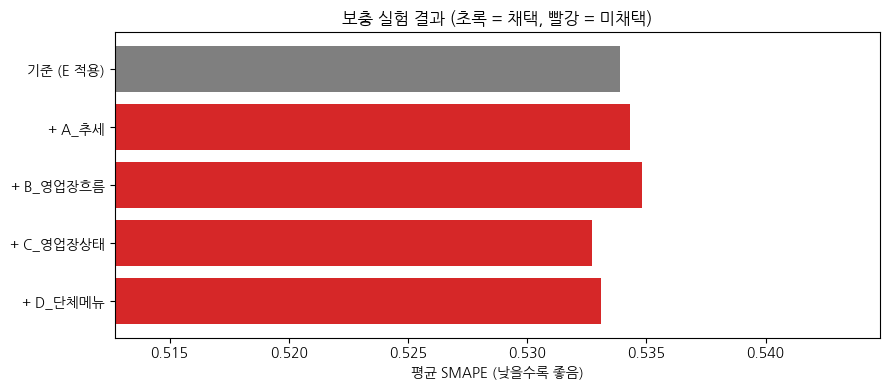

In [9]:
log_df = pd.DataFrame(LOG).set_index('단계')
display(log_df)
log_df.to_csv(RESULT_DIR / 'week3b_experiment_log.csv', encoding='utf-8-sig')
print('최종 채택된 새 피처:', [g for g, c in GROUPS.items() if set(c) <= set(best_cols)])
print(f'기준 {BASE_SCORES.mean().mean():.4f} → 최종 {best_scores.mean().mean():.4f}')

plt.figure(figsize=(9, 4))
colors = ['tab:gray'] + ['tab:green' if a == 'O' else 'tab:red' for a in log_df['채택'][1:]]
plt.barh(log_df.index[::-1], log_df['평균'][::-1], color=colors[::-1])
plt.xlim(log_df['평균'].min() - 0.02, log_df['평균'].max() + 0.01)
plt.xlabel('평균 SMAPE (낮을수록 좋음)'); plt.title('보충 실험 결과 (초록 = 채택, 빨강 = 미채택)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'w3_01_experiments.png', dpi=120); plt.show()

### 3주차와 비교: 같은 피처가 단순한 모델에서는 다르게 작동했나?

In [10]:
# 3주차(복잡한 모델) vs 보충 실험(단순한 모델): 같은 피처를 넣었을 때 차이(새 실험 − 기준) 비교
w3 = {'+ A_추세': 0.0010, '+ B_영업장흐름': 0.0006, '+ C_영업장상태': 0.0028, '+ D_단체메뉴': 0.0003}
# 하나씩 쌓기라서 각 단계의 기준은 '직전까지 채택된 상태'예요
rows = []
cur = LOG[0]['평균']
for r in LOG[1:]:
    rows.append({'실험': r['단계'], '3주차 평균 차이(복잡한 모델)': w3.get(r['단계']),
                 '보충 평균 차이(단순한 모델)': round(r['평균'] - cur, 4), '보충 판정': r['판정']})
    if r['채택'] == 'O':
        cur = r['평균']
display(pd.DataFrame(rows).set_index('실험'))
print('차이가 음수 = 좋아짐. 3주차보다 보충 실험에서 더 좋아졌다면 "단순한 모델 위에서 피처가 더 잘 통한다"는 뜻')

,3주차 평균 차이(복잡한 모델),보충 평균 차이(단순한 모델),보충 판정
실험,,,
+ A_추세,0.0010,0.0004,➖ 차이 없음 (노이즈 범위)
+ B_영업장흐름,0.0006,0.0009,➖ 차이 없음 (노이즈 범위)
+ C_영업장상태,0.0028,-0.0012,➖ 차이 없음 (노이즈 범위)
+ D_단체메뉴,0.0003,-0.0008,➖ 차이 없음 (노이즈 범위)


차이가 음수 = 좋아짐. 3주차보다 보충 실험에서 더 좋아졌다면 "단순한 모델 위에서 피처가 더 잘 통한다"는 뜻


## 7. 약점 다시 확인 (기준 vs 최종)
피처가 채택되지 않았다면 기준과 최종이 같아서 그래프가 겹쳐 보여요. 그것도 정상이에요.

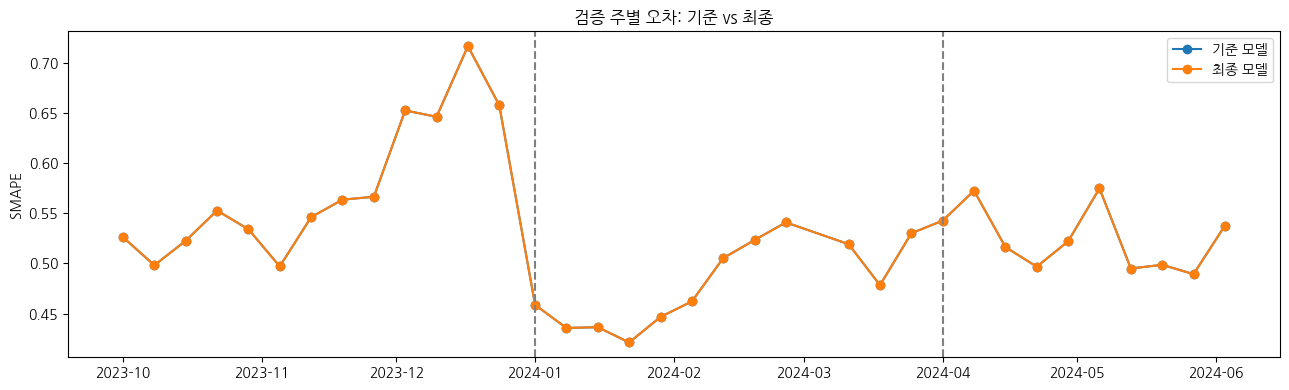

In [11]:
def long_errors(preds, seed=42):
    rows = []
    for fi, d in enumerate(FOLD_DATA):
        P = preds[(seed, fi)]
        if best_floor and preds is best_preds:
            P = np.maximum(P, 1)
        VW = np.stack([W[:, VENUE_IDX == j].sum(1) for j in range(V)], 1)
        for k, o in enumerate(d['val_o']):
            v_last7 = VW[o - 7:o].sum(0)[VENUE_IDX]; v_first21 = VW[o - INPUT_LEN:o - 7].sum(0)[VENUE_IDX]
            m28 = W[o - INPUT_LEN:o].sum(0); m7 = W[o - 7:o].sum(0)
            for h in range(HORIZON):
                rows.append(pd.DataFrame({'fold': fi + 1, 'window_start': DATES[o], 'menu': MENUS, 'venue': MENU_VENUE,
                                          'is_group': IS_GROUP, 'dow': DATES[o + h].dayofweek,
                                          'true': W[o + h], 'pred': P[k * HORIZON + h],
                                          'v7': v_last7, 'v21': v_first21, 'm28': m28, 'm7': m7}))
    e = pd.concat(rows, ignore_index=True)
    s = np.full(len(e), '⑤ 정상 판매', dtype=object)
    s[(e['m7'] == 0).values] = '④ 메뉴 최근 7일 0'
    s[(e['m28'] == 0).values] = '③ 메뉴만 28일 0'
    s[((e['v21'] == 0) & (e['v7'] > 0)).values] = '② 업장 재개장 직후'
    s[(e['v7'] == 0).values] = '① 업장 휴장 추정'
    e['상황'] = s
    e = e[e['true'] > 0].copy()
    e['smape'] = 2 * (e['true'] - e['pred']).abs() / (e['true'] + e['pred'])
    return e

e_base, e_best = long_errors(BASE_PREDS), long_errors(best_preds)

# 1) 주별 오차 (fold1 시즌 전환기)
wb = e_base.groupby('window_start')['smape'].mean(); wn = e_best.groupby('window_start')['smape'].mean()
plt.figure(figsize=(13, 4))
plt.plot(wb.index, wb.values, marker='o', label='기준 모델'); plt.plot(wn.index, wn.values, marker='o', label='최종 모델')
for a, _ in FOLDS[1:]:
    plt.axvline(pd.Timestamp(a), color='gray', linestyle='--')
plt.ylabel('SMAPE'); plt.title('검증 주별 오차: 기준 vs 최종'); plt.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'w3b_02_weekly_before_after.png', dpi=120); plt.show()

In [12]:
# 2) 상황별: 팔렸을 때 실제 vs 예측 중앙값, SMAPE
def sit_table(e):
    return e.groupby('상황').agg(채점건수=('smape', 'size'), 실제_중앙값=('true', 'median'),
                                예측_중앙값=('pred', 'median'), SMAPE=('smape', 'mean'))
cmp = sit_table(e_base).join(sit_table(e_best), lsuffix='_기준', rsuffix='_최종')
display(cmp[['실제_중앙값_기준', '예측_중앙값_기준', '예측_중앙값_최종', 'SMAPE_기준', 'SMAPE_최종']].round(3))

# 3) 단체 메뉴 / 요일
g = pd.DataFrame({'기준': e_base.groupby('is_group')['smape'].mean(), '최종': e_best.groupby('is_group')['smape'].mean()})
g.index = ['일반 메뉴', '단체 메뉴']; display(g.round(3))
dow_name = ['월', '화', '수', '목', '금', '토', '일']
dd = pd.DataFrame({'기준': e_base.groupby('dow')['smape'].mean(), '최종': e_best.groupby('dow')['smape'].mean()})
dd.index = dow_name; display(dd.T.round(3))
cmp.to_csv(RESULT_DIR / 'week3b_situation_before_after.csv', encoding='utf-8-sig')

,실제_중앙값_기준,예측_중앙값_기준,예측_중앙값_최종,SMAPE_기준,SMAPE_최종
상황,,,,,
① 업장 휴장 추정,3.0,3.016,3.016,0.541,0.541
② 업장 재개장 직후,37.0,17.629,17.629,0.632,0.632
③ 메뉴만 28일 0,4.0,4.543,4.543,0.731,0.731
④ 메뉴 최근 7일 0,1.0,1.698,1.698,0.490,0.490
⑤ 정상 판매,5.0,4.190,4.190,0.526,0.526


,기준,최종
일반 메뉴,0.521,0.521
단체 메뉴,0.656,0.656


,월,화,수,목,금,토,일
기준,0.549,0.54,0.538,0.55,0.527,0.494,0.507
최종,0.549,0.54,0.538,0.55,0.527,0.494,0.507


## 8. 최종 모델 & 제출 파일
채택된 피처가 없다면 3주차 최종 모델과 같은 설정이에요.

최종 모델 3개 학습 완료 | 학습 행 수: 319914


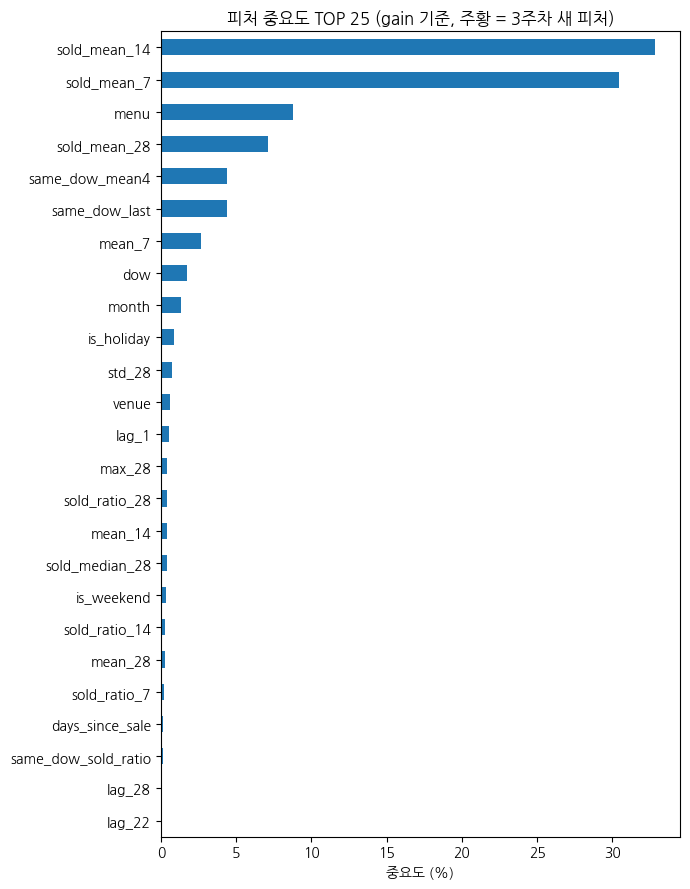

In [13]:
all_o = list(range(INPUT_LEN, len(DATES) - HORIZON + 1))
X_all, y_all = build_dataset(all_o)
mask = y_all > 0
final_models = []
for seed in SEEDS:                     # 시드 3개 모델을 만들어 예측을 평균 → 흔들림 감소
    mdl = lgb.LGBMRegressor(**best_params, random_state=seed)
    mdl.fit(X_all.loc[mask, best_cols], np.log1p(y_all[mask]))
    final_models.append(mdl)
print('최종 모델 3개 학습 완료 | 학습 행 수:', int(mask.sum()))

imp = pd.Series(np.mean([m.feature_importances_ for m in final_models], 0), index=best_cols)
imp = (imp / imp.sum() * 100).sort_values()
new_set = set(ALL_NEW)
plt.figure(figsize=(7, 9))
imp.tail(25).plot(kind='barh', color=['tab:orange' if c in new_set else 'tab:blue' for c in imp.tail(25).index])
plt.xlabel('중요도 (%)'); plt.title('피처 중요도 TOP 25 (gain 기준, 주황 = 3주차 새 피처)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'w3b_03_feature_importance.png', dpi=120); plt.show()

In [14]:
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
sub = sample.set_index('영업일자').astype(float)
cols_sub = [m for m in MENUS if m in sub.columns]
for f in sorted((DATA_DIR / 'test').glob('*TEST_*.csv')):
    tid = re.search(r'TEST_\d+', f.name).group()
    t = pd.read_csv(f); t['영업일자'] = pd.to_datetime(t['영업일자']); t['매출수량'] = t['매출수량'].clip(lower=0)
    tw = (t.pivot_table(index='영업일자', columns='영업장명_메뉴명', values='매출수량', aggfunc='sum')
            .sort_index().asfreq('D').reindex(columns=MENUS).fillna(0)).iloc[-INPUT_LEN:]
    start = tw.index.max() + pd.Timedelta(days=1)
    Xt = make_features(tw.values, start)[best_cols]
    pred = np.mean([np.clip(np.expm1(m.predict(Xt)), 0, None) for m in final_models], 0)
    if best_floor:
        pred = np.maximum(pred, 1)
    pred = pred.reshape(HORIZON, M)
    for h in range(1, HORIZON + 1):
        sub.loc[f'{tid}+{h}일', cols_sub] = pd.Series(pred[h - 1], index=MENUS)[cols_sub].values
    print(tid, '| 입력:', tw.index.min().date(), '~', tw.index.max().date())
sub.reset_index().to_csv(SUB_DIR / 'week3b_best.csv', index=False, encoding='utf-8-sig')
print('저장 완료:', SUB_DIR / 'week3b_best.csv')

TEST_00 | 입력: 2024-06-16 ~ 2024-07-13
TEST_01 | 입력: 2024-07-21 ~ 2024-08-17
TEST_02 | 입력: 2024-08-25 ~ 2024-09-21
TEST_03 | 입력: 2024-09-29 ~ 2024-10-26
TEST_04 | 입력: 2024-11-03 ~ 2024-11-30
TEST_05 | 입력: 2024-12-08 ~ 2025-01-04
TEST_06 | 입력: 2025-01-12 ~ 2025-02-08
TEST_07 | 입력: 2025-02-16 ~ 2025-03-15
TEST_08 | 입력: 2025-03-23 ~ 2025-04-19
TEST_09 | 입력: 2025-04-27 ~ 2025-05-24
저장 완료: /content/drive/MyDrive/capstone/submissions/week3b_best.csv


## 9. 정리 ✍️
| 실험 | 3주차 (복잡한 모델) | 보충 (단순한 모델) | 해석 |
|------|------------------|------------------|------|
| A 추세 | ➖ | | |
| B 영업장 흐름 | ➖ | | |
| C 영업장 상태 | ❌ | | |
| D 단체 메뉴 | ➖ | | |